# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr


## K-means Clustering


![K-means clustering](K-means.png)

### Discovering groups in two-dimensional data
- **Goal:** group similar observations using K-means without training on class labels.
- **Data:** two examples follow the original notebook: `x`, `y`; and `Feature_1`, `Feature_2`, with optional `True_Cluster` labels for evaluation only. 
- **Environment:** Python 3 with scikit-learn, pandas, NumPy, Matplotlib, seaborn, SciPy, joblib, and IPython.  
- **Setup if needed:** run `%pip install scikit-learn pandas numpy matplotlib seaborn scipy joblib ipython` in a separate cell, restart the kernel, and run this notebook from top to bottom.
- **Lesson route:** problem → inspect data → scale → understand K-means → select K → fit → interpret clusters → evaluate → predict → save/reload → optional hierarchical clustering.

| Concept | This K-means lesson |
|---|---|
| Learning type | Unsupervised clustering |
| Inputs | Numeric feature measurements |
| Training target | None |
| Model | K centroids and nearest-centroid assignments |
| Objective | Minimize within-cluster sum of squared distances |
| Output | Arbitrary cluster IDs and distances to centroids |
| Evaluation | Inertia, silhouette, and optional agreement with withheld reference labels |


### 1. Import libraries

- Import tools once and use the same plotting style throughout the lesson.
- Keep warnings visible so convergence and data problems can be investigated.


In [ ]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
pd.set_option("display.precision", 4)
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


- scikit-learn fits the clustering models; SciPy supports optional label matching and hierarchical clustering.


### 2. Configure the experiment

- Keep filenames, candidate cluster counts, and model settings in one place.
- Set either path to its CSV filename to use your own data. `None` uses a synthetic demonstration.
- Explicit `n_init` repeats initialization and retains the run with the lowest inertia.


In [3]:
RANDOM_STATE = 42
DATA_PATH_1 = None  # Optional: Path("clustering_dataset.csv")
DATA_PATH_2 = None  # Optional: Path("Clustering_dataset_2.csv")
FEATURES_1 = ["x", "y"]
FEATURES_2 = ["Feature_1", "Feature_2"]
K_VALUES = range(1, 10)
N_INIT = 10
MAX_ITER = 300
TOL = 1e-4
GRID_SIZE = 220
ARTIFACT_DIR = Path("kmeans_artifacts")

def make_kmeans(k, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, init="k-means++", n_init=N_INIT,
                  max_iter=MAX_ITER, tol=TOL, random_state=seed,
                  algorithm="lloyd")

**Hyperparameters:**
- `n_clusters` chooses the number of groups; it is not learned automatically by `KMeans`.
- `max_iter` limits assignment/update iterations within each initialization.
- `tol` controls the tolerance used for convergence; a fixed seed makes the demonstration reproducible.


## How K-means works
For observations $x_i$ and centroids $\mu_k$, the objective is

$$J=\sum_{i=1}^{n}\lVert x_i-\mu_{c_i}\rVert_2^2.$$

- **Centroid:** the mean feature vector of the observations assigned to a cluster.
- **Assignment:** set $c_i=\arg\min_k\lVert x_i-\mu_k\rVert_2^2$.
- **Update:** set $\mu_k=\frac{1}{|C_k|}\sum_{i\in C_k}x_i$.
- **Iteration:** alternate assignments and updates until convergence or the iteration limit.
- **K-means++:** selects initial centers with a spread-out, distance-based strategy; it does not guarantee the global optimum.
- **Local optimum:** different initializations can produce different partitions. Multiple starts reduce this risk.
- **Assumptions:** squared Euclidean distance favors compact groups and is sensitive to feature units, outliers, and unequal cluster shapes or densities.

Initialize → assign observations → update centroids → repeat.

K-means uses neither backpropagation nor a target-label loss such as cross-entropy.


## Example 1: Cluster observations with features `x` and `y`


### 3. Load and preview the first dataset

- Use one loading branch so a missing local file cannot silently overwrite or interrupt a working default.
- Synthetic group labels are deliberately discarded in this first unsupervised example.


In [4]:
from pathlib import Path
import pandas as pd

# Load the CSV file from the same folder as the notebook.
DATA_PATH_1 = Path("clustering_dataset.csv")

if not DATA_PATH_1.is_file():
    raise FileNotFoundError(f"Cannot find {DATA_PATH_1.resolve()}")

raw_df_1 = pd.read_csv(DATA_PATH_1)

print("Source:", DATA_PATH_1.resolve())
print("Rows and columns:", raw_df_1.shape)
display(raw_df_1.head())

Source: C:\Users\user\Documents\GitHub\AI\clustering_dataset.csv
Rows and columns: (300, 2)


,x,y
0,1.84,4.61
1,5.66,4.80
2,6.35,3.29
3,2.90,4.61
4,3.23,4.94


- Each row is one observation. Both columns are input features; there is no training target.


### 4. Validate numeric features and missing values

- Preserve the original data and explicitly select the feature columns.
- Stop on missing, nonnumeric, or infinite values. Negative and zero coordinates are valid here.
- Report duplicates without deleting them automatically; repeated measurements may represent real observations.


In [5]:
def validate_features(raw, columns):
    frame = raw.copy()
    frame.columns = frame.columns.astype(str).str.strip()
    if frame.columns.duplicated().any():
        raise ValueError("Duplicate column names after stripping whitespace.")
    missing = set(columns) - set(frame.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")
    values = frame[columns].apply(pd.to_numeric, errors="raise").astype(float)
    if not np.isfinite(values.to_numpy()).all():
        raise ValueError("Features must contain finite numbers with no missing values.")
    if len(values) < 4 or len(values.drop_duplicates()) < 3:
        raise ValueError("Use at least four observations and three distinct feature vectors.")
    if (values.nunique() < 2).any():
        raise ValueError("Each feature must vary for this two-dimensional lesson.")
    return frame, values

df_1, X_1 = validate_features(raw_df_1, FEATURES_1)
X_1.info()
display(X_1.isna().sum().to_frame("Missing values"))
print("Repeated feature rows:", X_1.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB


,Missing values
x,0
y,0


Repeated feature rows: 0


- If missing values need imputation, document the method and fit the imputer on the data used to fit the clustering model.


### 5. Summarize and explore the measurements

- Inspect ranges and distributions before choosing a distance representation.
- Use histograms rather than the removed seaborn `distplot` function.


,x,y
count,300.0000,300.0000
mean,3.6842,2.9874
std,1.9258,1.6850
min,-0.2450,0.2060
25%,2.1600,1.2150
50%,3.2300,2.9500
75%,5.5075,4.8100
max,8.2000,5.7800


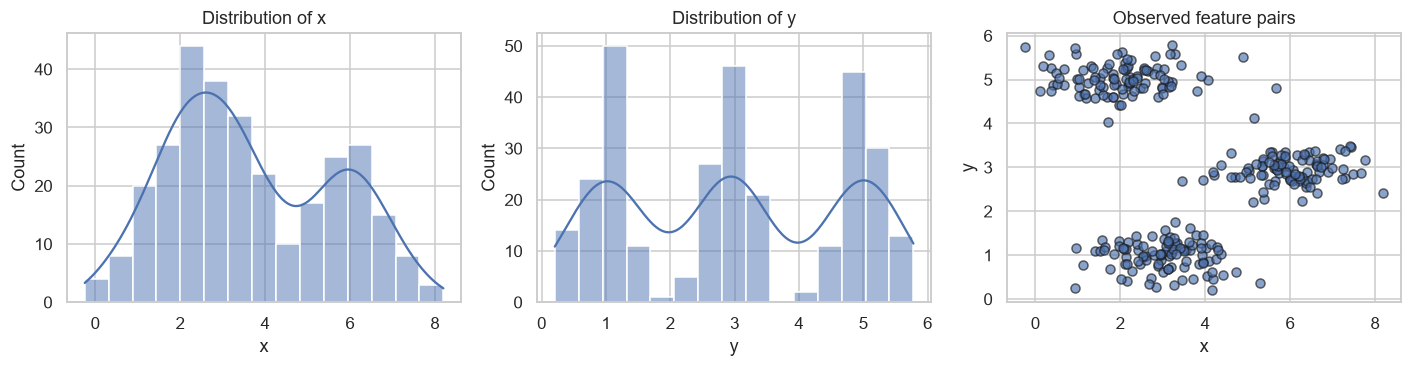

In [7]:
display(X_1.describe())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes[:2], FEATURES_1):
    sns.histplot(data=X_1, x=column, bins=15, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
axes[2].scatter(X_1["x"], X_1["y"], alpha=0.65, edgecolors="k", s=35)
axes[2].set(xlabel="x", ylabel="y", title="Observed feature pairs")
fig.tight_layout(); 
plt.show()

- Look for separated clouds, unusual points, and differences in feature spreads. A visible cloud does not by itself establish the correct number of clusters.


### 6. Standardize the features

- Apply $z=(x-\mu)/\sigma$ to each feature separately.
- Standardization gives features comparable influence by spread; it changes the meaning of distance and is a modeling choice.
- Use the fitted scaler for all later predictions and inverse-transform centroids for plots in original units.


In [8]:
scaler_1 = StandardScaler()
X_1_scaled = scaler_1.fit_transform(X_1)
display(pd.DataFrame({"Original mean": scaler_1.mean_,
    "Original standard deviation": scaler_1.scale_,
    "Scaled mean": X_1_scaled.mean(axis=0),
    "Scaled standard deviation": X_1_scaled.std(axis=0)}, index=FEATURES_1))
print("Input shape:", X_1_scaled.shape)

,Original mean,Original standard deviation,Scaled mean,Scaled standard deviation
x,3.6842,1.9226,0.0000e+00,1.0
y,2.9874,1.6822,-4.7370e-17,1.0


Input shape: (300, 2)


- Scaled means should be close to zero and standard deviations close to one. Standardization does not constrain values to [0, 1].


### 7. Inspect one assignment and centroid update

- Use a tiny one-dimensional example to make the optimization concrete.
- Compute squared distances, assign each point, then calculate the new means.


In [9]:
toy_points = np.array([[0.0], [2.0], [8.0], [10.0]])
toy_initial_centers = np.array([[0.0], [8.0]])
toy_squared_distances = ((toy_points[:, None, :] - toy_initial_centers[None, :, :]) ** 2).sum(axis=2)
toy_labels = toy_squared_distances.argmin(axis=1)
toy_updated_centers = np.array([toy_points[toy_labels == k].mean(axis=0) for k in range(2)])
display(pd.DataFrame({"Point": toy_points.ravel(),
    "Squared distance to center 0": toy_squared_distances[:, 0],
    "Squared distance to center 1": toy_squared_distances[:, 1],
    "Assigned cluster": toy_labels}))
print("Initial centers:", toy_initial_centers.ravel())
print("Updated centers:", toy_updated_centers.ravel())
print("SSE before update:", toy_squared_distances.min(axis=1).sum())
print("SSE after update:", ((toy_points - toy_updated_centers[toy_labels]) ** 2).sum())


,Point,Squared distance to center 0,Squared distance to center 1,Assigned cluster
0,0.0,0.0,64.0,0
1,2.0,4.0,36.0,0
2,8.0,64.0,0.0,1
3,10.0,100.0,4.0,1


Initial centers: [0. 8.]
Updated centers: [1. 9.]
SSE before update: 8.0
SSE after update: 4.0


- The updated means are 1 and 9. The objective decreases from 8 to 4; this illustrates one iteration, not a general proof of a global optimum.


## Inertia and silhouette
- **Inertia / SSE:** $J=\sum_i\lVert x_i-\mu_{c_i}\rVert^2$. Lower means tighter clusters in the chosen feature space. Compare values only for the same observations and preprocessing.
- Increasing K generally reduces the best achievable inertia; choosing the smallest observed inertia would favor excessive K. The **elbow** looks for diminishing improvement and can be ambiguous.
- For an observation, **$a(i)$** is its average distance to the other observations in its cluster. **$b(i)$** is the smallest average distance to observations in any other cluster.

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}.$$

- Silhouette ranges from −1 to +1: positive values suggest better within-cluster cohesion than separation to the nearest alternative; values near zero suggest overlap; negative values suggest a questionable assignment.
- scikit-learn assigns silhouette 0 to singleton clusters. Silhouette requires between 2 and $n-1$ realized clusters.
- The overall score is the mean across observations. There are no universal “good” or “excellent” thresholds, and the largest score need not reveal a uniquely true K.


### 8. Compare candidate values of K

- Fit each candidate on the same standardized features.
- Include K=1 for the elbow curve, but leave its silhouette undefined.
- Limit candidates to valid sample and distinct-point counts.


In [11]:
def compare_k(values):
    upper = min(max(K_VALUES), len(values) - 1, len(np.unique(values, axis=0)))
    rows = []
    for k in K_VALUES:
        if k > upper:
            continue
        candidate = make_kmeans(k)
        labels = candidate.fit_predict(values)
        realized = len(np.unique(labels))
        score = silhouette_score(values, labels) if 2 <= realized < len(values) else np.nan
        rows.append({"K": k, "Realized clusters": realized,
                     "Inertia": candidate.inertia_, "Silhouette": score,
                     "Iterations": candidate.n_iter_})
    return pd.DataFrame(rows)

k_table_1 = compare_k(X_1_scaled)
display(k_table_1)

c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows wi

,K,Realized clusters,Inertia,Silhouette,Iterations
0,1,1,600.0000,NaN,2
1,2,2,266.3407,0.5646,5
2,3,3,75.5484,0.7021,3
3,4,4,60.3186,0.6080,3
4,5,5,46.7785,0.5143,6
5,6,6,35.6393,0.4398,6
6,7,7,30.6590,0.4257,9
7,8,8,26.8953,0.4082,6
8,9,9,23.3007,0.4014,5


- These scores use feature geometry only. No species or reference labels are needed to fit or compare the candidates.


### 9. Plot the elbow and silhouette curves

- Inspect both compactness and separation rather than treating one curve as an automatic truth detector.
- Connect markers to make the trend across candidate values clear.


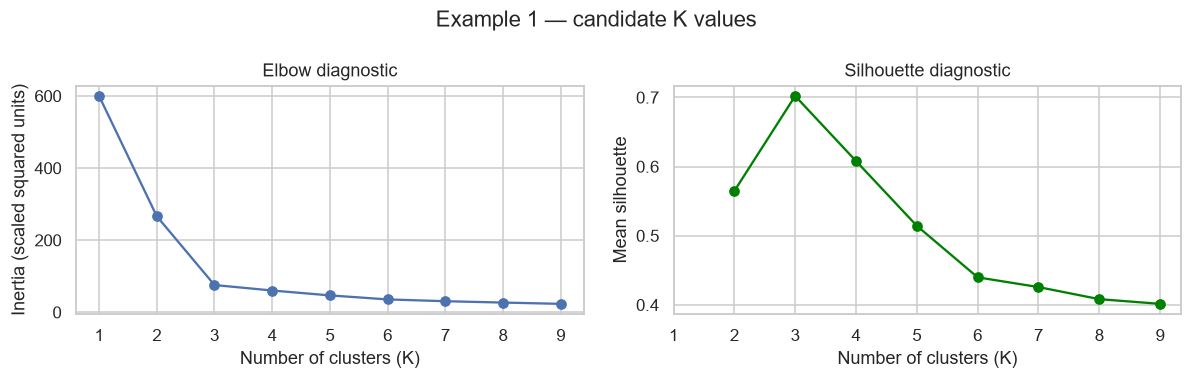

In [12]:
def plot_k_comparison(table, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(table["K"], table["Inertia"], "o-")
    axes[0].set(xlabel="Number of clusters (K)", ylabel="Inertia (scaled squared units)", title="Elbow diagnostic")
    valid = table.dropna(subset=["Silhouette"])
    axes[1].plot(valid["K"], valid["Silhouette"], "o-", color="green")
    axes[1].set(xlabel="Number of clusters (K)", ylabel="Mean silhouette", title="Silhouette diagnostic")
    for ax in axes:
        ax.set_xticks(table["K"])
    fig.suptitle(title); fig.tight_layout(); plt.show()

plot_k_comparison(k_table_1, "Example 1 — candidate K values")

- A clear elbow and high silhouette at the same K support that choice in this representation. Disagreement calls for inspecting the partitions and the application.


### 10. Select K and fit the first model

- For this reproducible lesson, select the highest silhouette among the tested candidates; ties favor the smaller K.
- Freeze that rule before examining any reference labels.
- Report convergence information and verify that the requested number of clusters was realized.


In [13]:
def select_k(table):
    valid = table.dropna(subset=["Silhouette"])
    if valid.empty:
        raise ValueError("No valid silhouette candidate; inspect the dataset.")
    ranked = valid.sort_values(["Silhouette", "K"], ascending=[False, True])
    return int(ranked.iloc[0]["K"])

selected_k_1 = select_k(k_table_1)
model_1 = make_kmeans(selected_k_1)
labels_1 = model_1.fit_predict(X_1_scaled)
centers_1_raw = scaler_1.inverse_transform(model_1.cluster_centers_)
assert len(np.unique(labels_1)) == selected_k_1
print("Selected K:", selected_k_1)
print("Iterations:", model_1.n_iter_, "of", MAX_ITER)
print("Inertia:", model_1.inertia_)
display(pd.DataFrame(centers_1_raw, columns=FEATURES_1).rename_axis("Cluster"))

Selected K: 3
Iterations: 3 of 300
Inertia: 75.54844203527053


c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,x,y
Cluster,,
0,3.0343,0.9988
1,6.0247,2.9732
2,1.9830,5.0305


- Cluster IDs such as 0 and 1 are arbitrary names, not ordered quantities. Reaching the iteration limit should prompt a convergence check.


### 11. Verify SSE and summarize each cluster

- Calculate distances in the same scaled space used for fitting.
- Sum each cluster’s squared distances and verify agreement with the model inertia.
- Report centroids and descriptive statistics in original feature units.


In [14]:
def cluster_details(raw_features, values, fitted_model):
    labels = fitted_model.predict(values)
    distances = fitted_model.transform(values)
    result = raw_features.copy()
    result["Cluster"] = labels
    result["Distance to centroid (scaled)"] = distances[np.arange(len(values)), labels]
    result["Silhouette"] = silhouette_samples(values, labels)
    return result

results_1 = cluster_details(X_1, X_1_scaled, model_1)
sse_1 = results_1.groupby("Cluster")["Distance to centroid (scaled)"].apply(lambda s: np.square(s).sum())
np.testing.assert_allclose(sse_1.sum(), model_1.inertia_, rtol=1e-7)
display(sse_1.to_frame("SSE (scaled squared units)"))
display(results_1.groupby("Cluster")[FEATURES_1].agg(["count", "mean", "std", "min", "max"]))

,SSE (scaled squared units)
Cluster,
0,25.1674
1,22.4148
2,27.9662


x                                  y                             
        count    mean     std    min   max count    mean     std    min   max
Cluster                                                                      
0         101  3.0343  0.8667  0.946  5.29   101  0.9988  0.3704  0.206  2.68
1         100  6.0247  0.8221  3.960  8.20   100  2.9732  0.3511  2.200  4.80
2          99  1.9830  0.9578 -0.245  4.89    99  5.0305  0.3244  4.040  5.78

- A centroid distance is not a probability. Large distances identify points to inspect, but do not establish that an observation is incorrect or anomalous.


### 12. Visualize clusters and nearest-centroid regions

- Create a fixed-resolution grid to avoid excessive memory use.
- Transform raw grid coordinates with the fitted scaler before predicting regions.
- Plot inverse-transformed centroids alongside raw observations.


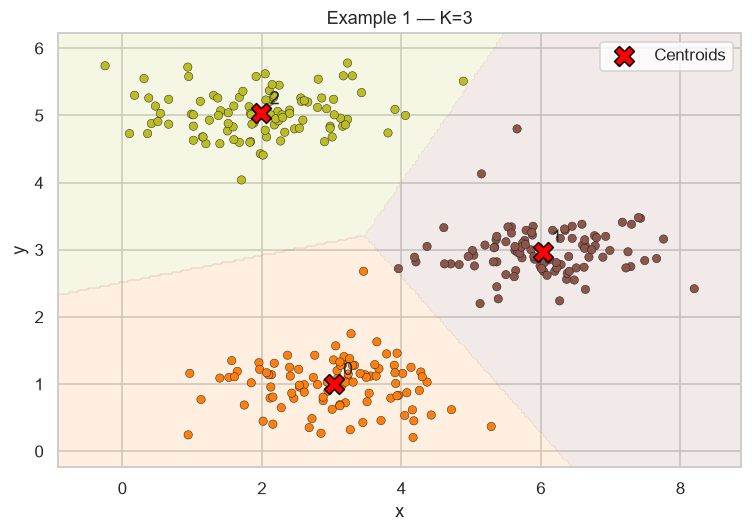

In [15]:
def plot_partition(raw_features, fitted_scaler, fitted_model, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    columns = list(raw_features.columns)
    low = raw_features.min().to_numpy()
    high = raw_features.max().to_numpy()
    padding = 0.08 * (high - low)
    xx, yy = np.meshgrid(np.linspace(low[0]-padding[0], high[0]+padding[0], GRID_SIZE),
                         np.linspace(low[1]-padding[1], high[1]+padding[1], GRID_SIZE))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=columns)
    region = fitted_model.predict(fitted_scaler.transform(grid)).reshape(xx.shape)
    k = fitted_model.n_clusters
    levels = np.arange(k + 1) - 0.5
    ax.contourf(xx, yy, region, levels=levels, cmap="tab10", alpha=0.12, vmin=-0.5, vmax=k-0.5)
    labels = fitted_model.predict(fitted_scaler.transform(raw_features))
    ax.scatter(raw_features.iloc[:, 0], raw_features.iloc[:, 1], c=labels,
               cmap="tab10", vmin=-0.5, vmax=k-0.5, s=30, edgecolors="k", linewidths=0.3)
    centers = fitted_scaler.inverse_transform(fitted_model.cluster_centers_)
    ax.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=170, edgecolors="black", label="Centroids")
    for cluster, center in enumerate(centers):
        ax.annotate(str(cluster), center, xytext=(6, 6), textcoords="offset points")
    ax.set(xlabel=columns[0], ylabel=columns[1], title=title)
    ax.legend()
    return ax

plot_partition(X_1, scaler_1, model_1, f"Example 1 — K={selected_k_1}")
plt.tight_layout(); 
plt.show()

- The shaded regions show where the fitted model assigns new points. They extend beyond the observed clouds and do not imply that those empty locations contain data.


### 13. Compare the original K=3 and K=5 examples

- Retain the original notebook’s explicit comparison using separate model variables.
- Avoid overwriting the selected model while exploring alternatives.
- Skip any demonstration K that is too large for a custom dataset.


c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


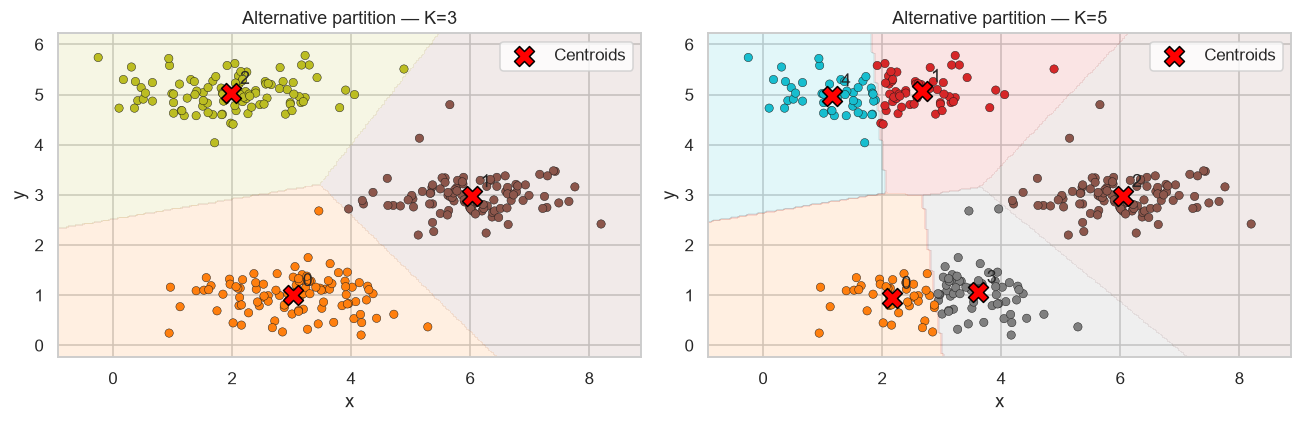

,K,Inertia,Silhouette
0,3,75.5484,0.7021
1,5,46.7785,0.5143


In [16]:
demo_ks = [k for k in [3, 5] if k < len(X_1_scaled) and k <= len(np.unique(X_1_scaled, axis=0))]
fig, axes = plt.subplots(1, len(demo_ks), figsize=(6 * len(demo_ks), 4), squeeze=False)
comparison_rows = []
for ax, k in zip(axes.ravel(), demo_ks):
    comparison_model = make_kmeans(k).fit(X_1_scaled)
    plot_partition(X_1, scaler_1, comparison_model, f"Alternative partition — K={k}", ax)
    comparison_rows.append({"K": k, "Inertia": comparison_model.inertia_,
        "Silhouette": silhouette_score(X_1_scaled, comparison_model.labels_)})
fig.tight_layout(); plt.show()
display(pd.DataFrame(comparison_rows))

- K=5 can split a coherent cloud into smaller parts. A lower inertia alone does not make it a more useful partition than K=3.
